<a href="https://colab.research.google.com/github/23-prasad/EnMAP-Sentinel2-Fusion-Pipeline/blob/main/EnMAP_S2_fusion_pipeline_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EnMAP hyperspectral processing and Sentinel-2 fusion | Potsdam urban land cover

**Project type:** reproducible learning pipeline / methods demonstrator  
**Platform:** Google Colab or Jupyter Notebook  
**Study area:** Potsdam, Germany  
**Data:** EnMAP L2A, Sentinel-2 L2A, and land-cover reference polygons from the EnMAP-Box examples

## Data credits: 
1. EnMAP data © DLR 2022 (EnMAP-Box example dataset) ·
2. Contains modified Copernicus Sentinel data 2022 ·
3. Land-cover reference: GeoBasis-DE/LGB, dl-de/by-2-0 (data modified)

## Research question

Does combining EnMAP hyperspectral information with Sentinel-2 multispectral observations improve **six-class urban land-cover classification** or **sub-pixel vegetation-fraction estimation**, compared with either sensor alone?

This notebook implements a complete Python workflow from freely accessible input data to mapped outputs. **Fusion means feature-level concatenation**, not spatial sharpening or reconstruction of a higher-resolution hyperspectral image.

### Workflow at a glance

1. Download and inspect the EnMAP cube and reference data.
2. Remove flagged / strongly absorbed spectral bands and smooth valid spectral segments.
3. Convert reference polygons into 30 m class-fraction targets.
4. Derive spectral indices and principal components.
5. Assess EnMAP-only classification using grouped spatial cross-validation.
6. Query Sentinel-2 through the public Earth Search STAC endpoint and place bands on the EnMAP grid.
7. Check cross-sensor agreement; compare standalone and stacked-feature Random Forest models.
8. Estimate vegetation fraction and export maps, accuracy tables and a trained classifier.

**Reproducibility note:** the notebook requires internet access for input downloads. Sentinel-2 retrieval can fail in restricted environments; the code then substitutes *simulated Sentinel-2 bands derived from EnMAP*. Such a run validates code execution **but is not an independent sensor-fusion experiment**. Confirm the output `s2_is_real` is `True` before using metrics as actual two-sensor findings.

**Reading the results:** accuracy values in this notebook pertain to one scene / study area. Fold-to-fold uncertainty was not estimated. The PCA transformation is fitted on image pixels before cross-validation; consequently, spatial CV estimates are exploratory and should not be described as a leakage-free evaluation of a full train-to-test pipeline.

**Source data:** see the accompanying repository README for dataset identifiers, provenance and attribution. No account credentials are embedded in this notebook.

## 0 · Setup

In [ ]:
# Colab already has numpy/pandas/sklearn/matplotlib/scipy; this adds the geospatial packages.
%pip install -q rasterio geopandas pystac-client

In [ ]:
import os, json, warnings, urllib.request
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import shapely
import rasterio
from rasterio.features import rasterize
from rasterio.vrt import WarpedVRT
from rasterio.warp import Resampling, transform_bounds
from affine import Affine
from scipy.signal import savgol_filter
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score,
                             ConfusionMatrixDisplay, r2_score, mean_squared_error)
import joblib

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

**Configuration and execution.** Run cells in order. Adjust paths and parameters in `CFG` below. The default working folders are ephemeral in Colab; download exported results at the end of the notebook or mount Google Drive for persistence.

If using Drive, mount it **before** the configuration cell, then change `data_dir` and `out_dir` *inside* `CFG` (or update them and recreate the directories before downloads). For example:

```python
from google.colab import drive
drive.mount('/content/drive')
# Then edit CFG: data_dir='/content/drive/MyDrive/enmap_pipeline/data', etc.
```

The workflow uses a public EnMAP-Box sample and anonymous Sentinel-2 STAC access; remote services and packages can change.

In [ ]:
CFG = dict(
    data_dir="data",
    out_dir="outputs",
    base_url="https://raw.githubusercontent.com/EnMAP-Box/enmap-box/main/enmapbox/exampledata/",
    enmap_file="enmap_potsdam.tif",
    labels_file="landcover_potsdam_polygon.gpkg",
    labels_layer="landcover_potsdam_polygon",
    label_level="level_3",          # level_1 (4 classes), level_2 (5), level_3 (6)
    enmap_scale=10000.0,            # L2A stores reflectance x 10000
    # Sentinel-2
    s2_source="stac",               # "stac" = real Sentinel-2; "simulate" = offline test from EnMAP
    stac_url="https://earth-search.aws.element84.com/v1",
    s2_window_days=25,              # search +/- days around the EnMAP date
    s2_max_cloud=30,                # scene-level cloud cover filter (%)
    # Machine learning
    fine_factor=10,                 # rasterise labels at 30 m / 10 = 3 m to get class fractions
    min_coverage=0.95,              # pixel must be >= 95 % covered by reference polygons
    min_purity=0.70,                # ... and >= 70 % one class to be a classification sample
    block_px=20,                    # spatial CV block size (20 px = 600 m)
    n_folds=4,
    max_samples=15000,              # cap on training samples (keeps RF fast)
    n_trees=150,
    random_state=42,
)
os.makedirs(CFG["data_dir"], exist_ok=True)
os.makedirs(CFG["out_dir"], exist_ok=True)
rng = np.random.default_rng(CFG["random_state"])

def download(fname):
    path = os.path.join(CFG["data_dir"], fname)
    if not os.path.exists(path):
        print("downloading", fname, "...")
        urllib.request.urlretrieve(CFG["base_url"] + fname, path)
    return path

enmap_path = download(CFG["enmap_file"])
labels_path = download(CFG["labels_file"])
print("ready:", enmap_path, labels_path)

downloading enmap_potsdam.tif ...
downloading landcover_potsdam_polygon.gpkg ...
ready: data/enmap_potsdam.tif data/landcover_potsdam_polygon.gpkg


## 1 · Load the EnMAP cube

**Learn.** An EnMAP L2A product is a surface-reflectance *cube*: 224 bands from ~420 to 2445 nm.
Each band carries metadata: centre **wavelength**, **FWHM** (bandwidth) and a **bad-band flag** (`bbl`).
Two detectors are stacked: **VNIR** (≈420–990 nm) and **SWIR** (≈900–2445 nm), so the wavelength list is *not* monotonic where they overlap.

In [ ]:
def load_enmap(path, scale):
    with rasterio.open(path) as src:
        cube = src.read().astype("float32")                 # (bands, rows, cols)
        tags = [src.tags(b) for b in range(1, src.count + 1)]
        meta = dict(profile=src.profile.copy(), crs=src.crs, transform=src.transform,
                    bounds=src.bounds, date=src.tags().get("start_time"), nodata=src.nodata)
    wl = np.array([float(t["wavelength"]) for t in tags])
    fwhm = np.array([float(t.get("fwhm", "nan")) for t in tags])
    bbl = np.array([int(float(t.get("bbl", 1))) for t in tags])
    if meta["nodata"] is not None:
        cube[cube == meta["nodata"]] = np.nan
    cube /= scale                                          # -> reflectance 0..1
    return cube, wl, fwhm, bbl, meta

cube, wl, fwhm, bbl, meta = load_enmap(enmap_path, CFG["enmap_scale"])
nb, rows, cols = cube.shape
enmap_date = datetime.fromisoformat(meta["date"])
print(f"{nb} bands, {rows} x {cols} px, {meta['crs']}, acquired {enmap_date:%Y-%m-%d %H:%M} UTC")
print(f"wavelengths {wl.min():.0f}-{wl.max():.0f} nm, FWHM {np.nanmin(fwhm):.1f}-{np.nanmax(fwhm):.1f} nm, "
      f"flagged bad bands: {(bbl == 0).sum()}")
vnir_end = int(np.where(np.diff(wl) <= 0)[0][0])
print(f"VNIR ends at band {vnir_end} ({wl[vnir_end]:.0f} nm); SWIR starts at {wl[vnir_end + 1]:.0f} nm")

224 bands, 200 x 330 px, EPSG:32633, acquired 2022-07-24 10:45 UTC
wavelengths 418-2446 nm, FWHM 5.8-11.4 nm, flagged bad bands: 6
VNIR ends at band 90 (993 nm); SWIR starts at 902 nm


## 2 · Explore: composites and spectra

**Learn.** With hundreds of bands you choose bands *by wavelength*, not by number.
True colour ≈ 650/560/470 nm; colour-infrared (CIR) ≈ 860/650/560 nm — vegetation turns red because healthy leaves reflect strongly in the NIR.

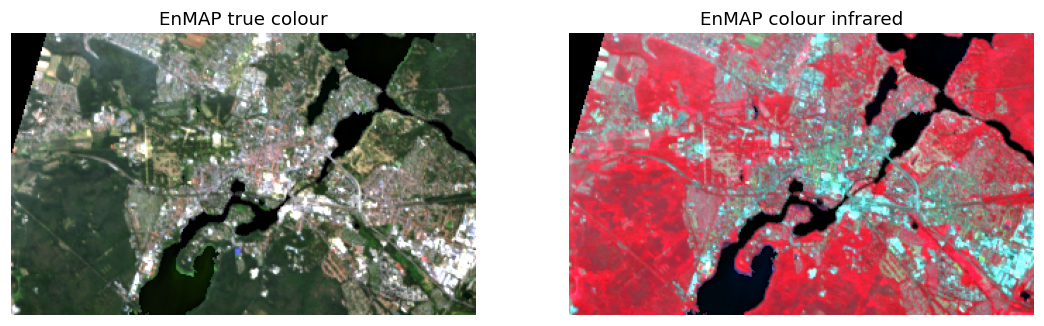

In [ ]:
def band_at(nm, mask=None):
    # index of the band closest to `nm` (optionally only among bands where mask is True)
    d = np.abs(wl - nm).astype(float)
    if mask is not None:
        d[~mask] = np.inf
    return int(np.argmin(d))

def stretch(img, p=(2, 98)):
    out = np.zeros(img.shape, dtype="float32")
    for i in range(img.shape[-1]):
        lo, hi = np.nanpercentile(img[..., i], p)
        out[..., i] = np.clip((img[..., i] - lo) / (hi - lo + 1e-9), 0, 1)
    return np.nan_to_num(out)

def composite(c, nms):
    return stretch(np.dstack([c[band_at(n)] for n in nms]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(composite(cube, (650, 560, 470))); ax[0].set_title("EnMAP true colour")
ax[1].imshow(composite(cube, (860, 650, 560))); ax[1].set_title("EnMAP colour infrared")
for a in ax: a.axis("off")
plt.show()

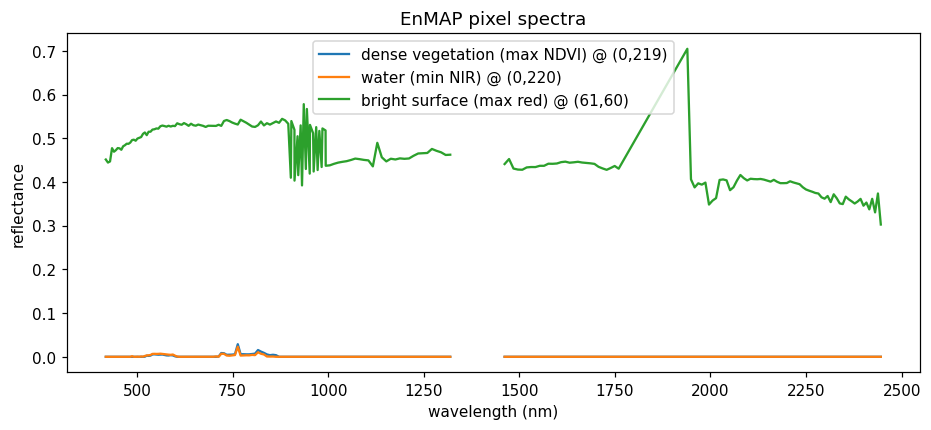

In [ ]:
# Pick a few characteristic pixels automatically and plot their spectra
nir, red = cube[band_at(860)], cube[band_at(665)]
ndvi_quick = (nir - red) / (nir + red)
picks = {
    "dense vegetation (max NDVI)": np.unravel_index(np.nanargmax(ndvi_quick), ndvi_quick.shape),
    "water (min NIR)": np.unravel_index(np.nanargmin(nir), nir.shape),
    "bright surface (max red)": np.unravel_index(np.nanargmax(red), red.shape),
}
order = np.argsort(wl)                                     # sort to draw VNIR+SWIR as one line
plt.figure(figsize=(10, 4))
for name, (r, c) in picks.items():
    plt.plot(wl[order], cube[order, r, c], label=f"{name} @ ({r},{c})")
plt.xlabel("wavelength (nm)"); plt.ylabel("reflectance"); plt.legend(); plt.title("EnMAP pixel spectra")
plt.show()

## 3 · Pre-processing: bad bands and spectral smoothing

**Learn.** Around **1400 nm** and **1900 nm** atmospheric water vapour absorbs almost all light,
so those bands are mostly noise. We remove flagged bands *and* these windows.
A **Savitzky–Golay** filter then smooths each spectrum, applied separately per contiguous segment
(and per detector) so that it never smooths across a gap.

keeping 210 of 224 bands (removed: 6 flagged, 8 in water-vapour windows)
valid pixels: 98.3%


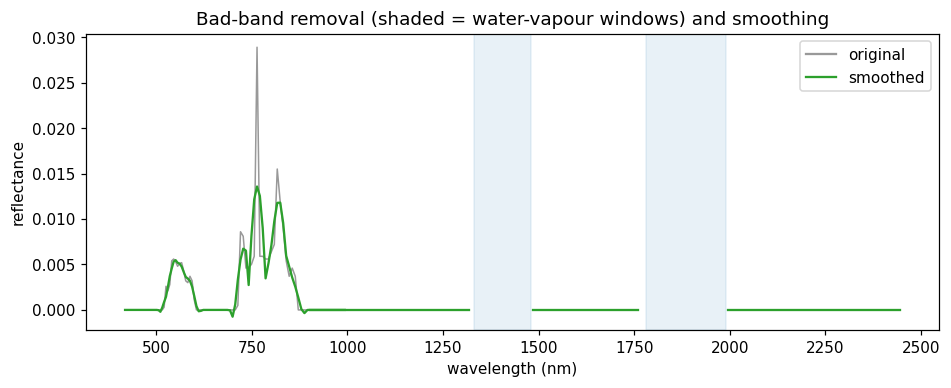

In [ ]:
WATER_WINDOWS = [(1330, 1480), (1780, 1990)]
in_window = np.zeros(nb, bool)
for a, b in WATER_WINDOWS:
    in_window |= (wl >= a) & (wl <= b)
all_nan = np.all(np.isnan(cube), axis=(1, 2))
good = (bbl == 1) & ~in_window & ~all_nan
print(f"keeping {good.sum()} of {nb} bands (removed: {(bbl == 0).sum()} flagged, "
      f"{(in_window & (bbl == 1)).sum()} in water-vapour windows)")

def segments(mask):
    # contiguous runs of good bands, also split where the wavelength jumps back (VNIR->SWIR)
    idx = np.where(mask)[0]
    breaks = np.where((np.diff(idx) > 1) | (np.diff(wl[idx]) <= 0))[0] + 1
    return np.split(idx, breaks)

def smooth_cube(c, mask, window=7, order=2):
    out = c.copy()
    for seg in segments(mask):
        if len(seg) >= window:
            block = c[seg]
            nan = np.isnan(block)
            sm = savgol_filter(np.nan_to_num(block), window, order, axis=0)   # filter needs finite values
            sm[nan] = np.nan                                                # restore no-data
            out[seg] = sm
    return out

cube_s = smooth_cube(cube, good)
valid = np.all(np.isfinite(cube_s[good]), axis=0)        # pixels with a complete spectrum
print(f"valid pixels: {valid.mean():.1%}")

r, c = picks["dense vegetation (max NDVI)"]
plt.figure(figsize=(10, 3.5))
for seg in segments(good):
    plt.plot(wl[seg], cube[seg, r, c], color="0.6", lw=1)
    plt.plot(wl[seg], cube_s[seg, r, c], color="C2", lw=1.5)
for a, b in WATER_WINDOWS:
    plt.axvspan(a, b, color="C0", alpha=0.1)
plt.plot([], [], color="0.6", label="original"); plt.plot([], [], color="C2", label="smoothed")
plt.legend(); plt.xlabel("wavelength (nm)"); plt.ylabel("reflectance")
plt.title("Bad-band removal (shaded = water-vapour windows) and smoothing"); plt.show()

## 4 · Reference labels → class fractions per pixel

**Learn.** The reference polygons were digitised on 1 m aerial imagery, so most 30 m EnMAP pixels contain
**several classes** (mixed pixels). Instead of simply burning polygons into the 30 m grid, we rasterise at
3 m and aggregate. This gives, for every pixel, the **fraction** of each class. We use:

* **pure pixels** (one class ≥ 70 %) as classification samples, and
* the **vegetation fraction** as a continuous target for regression later (section 11).

classes: {'low vegetation': 1, 'pavement': 2, 'roof': 3, 'soil': 4, 'tree': 5, 'water': 6}
pixels fully covered by reference: 5469, pure pixels for classification: 2769
tree              1453
low vegetation     615
water              323
pavement           253
roof                80
soil                45


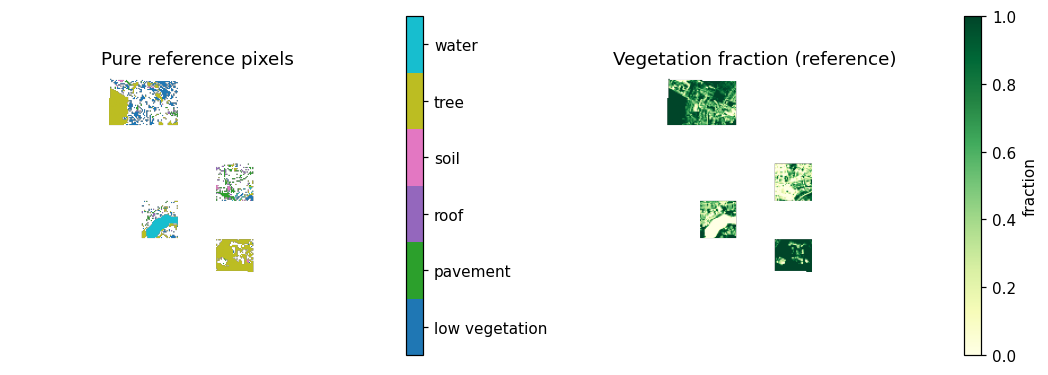

In [ ]:
gdf = gpd.read_file(labels_path, layer=CFG["labels_layer"]).to_crs(meta["crs"])
gdf["geometry"] = shapely.force_2d(gdf.geometry.values)
classes = sorted(gdf[CFG["label_level"]].unique())
code_of = {name: i + 1 for i, name in enumerate(classes)}
print("classes:", code_of)

F = CFG["fine_factor"]
fine = rasterize(
    ((geom, code_of[lab]) for geom, lab in zip(gdf.geometry, gdf[CFG["label_level"]])),
    out_shape=(rows * F, cols * F),
    transform=meta["transform"] * Affine.scale(1 / F),
    fill=0, dtype="uint8")

frac = np.stack([(fine == k).reshape(rows, F, cols, F).mean(axis=(1, 3))
                 for k in range(1, len(classes) + 1)]).astype("float32")   # (classes, rows, cols)
coverage = frac.sum(0)
dominant = frac.argmax(0) + 1
purity = frac.max(0)
veg_names = [n for n in classes if n in ("low vegetation", "tree", "vegetation")]
veg_frac = frac[[classes.index(n) for n in veg_names]].sum(0)

covered = (coverage >= CFG["min_coverage"]) & valid
train_cls = covered & (purity >= CFG["min_purity"])
print(f"pixels fully covered by reference: {covered.sum()}, pure pixels for classification: {train_cls.sum()}")
print(pd.Series(dominant[train_cls]).map(dict(enumerate(classes, 1))).value_counts().to_string())

cmap = plt.get_cmap("tab10", len(classes))
lab_map = np.where(train_cls, dominant, np.nan)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].imshow(lab_map, cmap=cmap, vmin=0.5, vmax=len(classes) + 0.5)
cb = fig.colorbar(im, ax=ax[0], ticks=range(1, len(classes) + 1)); cb.ax.set_yticklabels(classes)
ax[0].set_title("Pure reference pixels")
im = ax[1].imshow(np.where(covered, veg_frac, np.nan), cmap="YlGn", vmin=0, vmax=1)
fig.colorbar(im, ax=ax[1], label="fraction"); ax[1].set_title("Vegetation fraction (reference)")
for a in ax: a.axis("off")
plt.show()

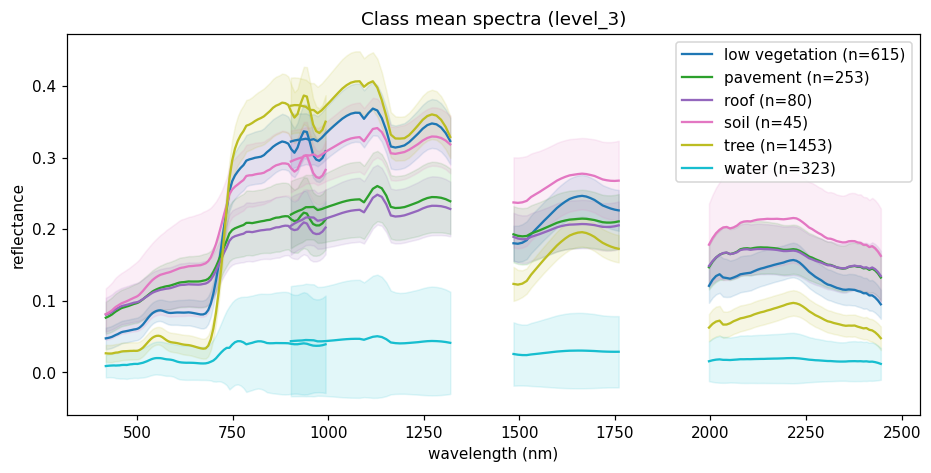

In [ ]:
# Mean spectrum (+/- 1 std) of each class from the pure pixels
plt.figure(figsize=(10, 4.5))
for k, name in enumerate(classes, 1):
    sel = train_cls & (dominant == k)
    if sel.sum() == 0:
        continue
    spec = cube_s[:, sel]
    m, s = np.nanmean(spec, 1), np.nanstd(spec, 1)
    for j, seg in enumerate(segments(good)):
        plt.plot(wl[seg], m[seg], color=cmap(k - 1), label=f"{name} (n={sel.sum()})" if j == 0 else None)
        plt.fill_between(wl[seg], (m - s)[seg], (m + s)[seg], color=cmap(k - 1), alpha=0.12)
plt.xlabel("wavelength (nm)"); plt.ylabel("reflectance"); plt.legend()
plt.title(f"Class mean spectra ({CFG['label_level']})"); plt.show()

## 5 · Spectral indices

**Learn.** Hyperspectral data lets you use **narrow-band** indices that broadband sensors cannot compute well,
e.g. the **red-edge position (REP)** — the wavelength of the steep rise between red and NIR, which shifts with
chlorophyll content — or the **PRI** (photochemical reflectance index, 531/570 nm), linked to plant stress.

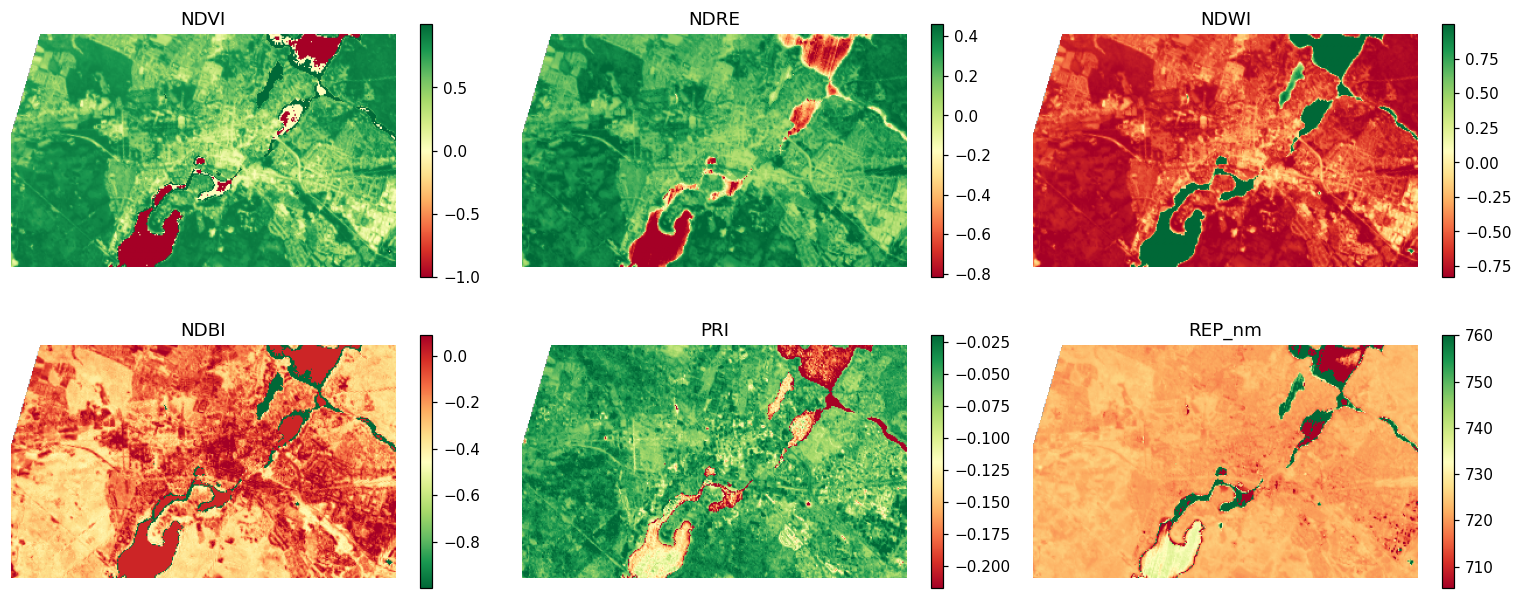

In [ ]:
def R(c, nm):
    return c[band_at(nm, good)]

def nd(a, b):
    return (a - b) / (a + b + 1e-9)

def enmap_indices(c):
    r670, r700, r740, r780 = R(c, 670), R(c, 700), R(c, 740), R(c, 780)
    rep = 700 + 40 * (((r670 + r780) / 2 - r700) / (r740 - r700 + 1e-9))   # Guyot & Baret linear REP
    return {
        "NDVI":  nd(R(c, 865), R(c, 665)),
        "NDRE":  nd(R(c, 790), R(c, 720)),
        "NDWI":  nd(R(c, 560), R(c, 865)),
        "NDBI":  nd(R(c, 1650), R(c, 865)),
        "PRI":   nd(R(c, 531), R(c, 570)),
        "REP_nm": np.clip(rep, 680, 760),
    }

idx_e = enmap_indices(cube_s)
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, (name, arr) in zip(ax.ravel(), idx_e.items()):
    vmin, vmax = np.nanpercentile(arr, (2, 98))
    im = a.imshow(arr, cmap="RdYlGn" if name != "NDBI" else "RdYlGn_r", vmin=vmin, vmax=vmax)
    a.set_title(name); a.axis("off"); fig.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()

## 6 · Principal component analysis (PCA)

**Method.** Neighbouring hyperspectral bands are correlated. PCA compresses spectral variation into orthogonal components; the number retained here follows the cumulative-variance threshold with a minimum of ten components.

**Evaluation caveat.** In this learning notebook, PCA is fitted **once on image pixels before spatial cross-validation**. Although it does not use class labels, it incorporates the feature distribution of held-out locations. For a stricter inductive performance estimate, fit PCA separately on each training fold using an `sklearn.pipeline.Pipeline`, then apply that fitted transformation to its test fold. The reported PCA/fusion scores are therefore exploratory.

3 components explain 99 % of the variance; using 10 PCs (99.9 %, min 10) as ML features


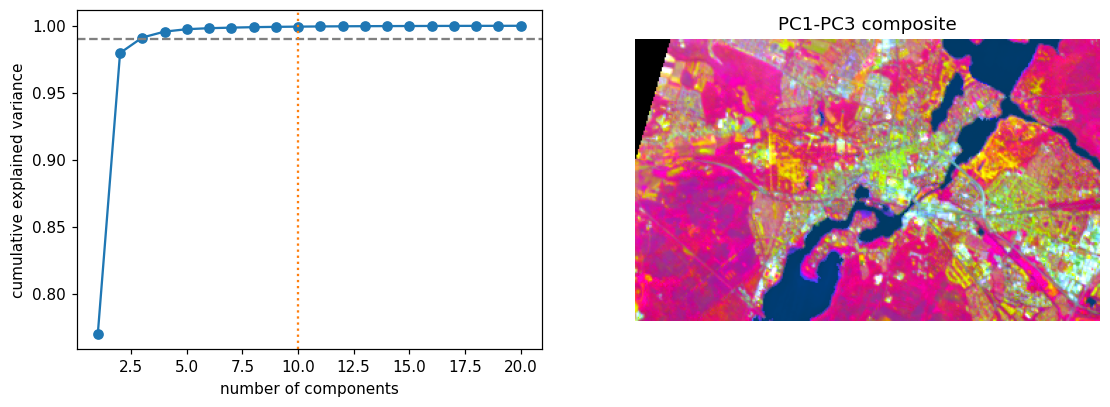

In [ ]:
def flat(img3, mask):
    # (features, rows, cols) -> (pixels, features) for pixels in mask
    return img3[:, mask].T

def unflat(values, mask, fill=np.nan):
    # (pixels,) or (pixels, features) -> image(s) with `fill` outside mask
    if values.ndim == 1:
        out = np.full(mask.shape, fill, dtype="float32"); out[mask] = values
    else:
        out = np.full((values.shape[1],) + mask.shape, fill, dtype="float32"); out[:, mask] = values.T
    return out

X_spec_all = flat(cube_s[good], valid)
pca = PCA(n_components=20, random_state=CFG["random_state"]).fit(
    X_spec_all[rng.choice(len(X_spec_all), min(30000, len(X_spec_all)), replace=False)])
pcs = unflat(pca.transform(X_spec_all), valid)              # (20, rows, cols)
cum = np.cumsum(pca.explained_variance_ratio_)
n99 = int(np.searchsorted(cum, 0.99) + 1)
n_pc = max(10, int(np.searchsorted(cum, 0.999) + 1))      # keep more PCs for ML: small PCs carry subtle material info
print(f"{n99} components explain 99 % of the variance; using {n_pc} PCs (99.9 %, min 10) as ML features")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 21), cum, "o-"); ax[0].axhline(0.99, ls="--", c="0.5"); ax[0].axvline(n_pc, ls=":", c="C1")
ax[0].set_xlabel("number of components"); ax[0].set_ylabel("cumulative explained variance")
ax[1].imshow(stretch(np.dstack([pcs[0], pcs[1], pcs[2]]))); ax[1].set_title("PC1-PC3 composite"); ax[1].axis("off")
plt.show()

## 7 · EnMAP-only classification and spatial cross-validation

**Why group pixels spatially?** Nearby pixels tend to resemble one another. A random pixel split can overstate performance by placing highly similar neighbours in training and testing sets. This notebook groups samples into approximately **600 m × 600 m blocks** and holds out groups using four folds.

**Scope of the validation.** This is more spatially aware than an ordinary random pixel split, but it does not prove transfer to another city, acquisition date or sensor scene. The PCA preprocessing used later in the comparison is also not refitted within folds; see section 6.

{'features': 'EnMAP (all good bands)', 'n_features': 210, 'OA': 0.876, 'kappa': np.float64(0.809), 'macro_F1': 0.595}


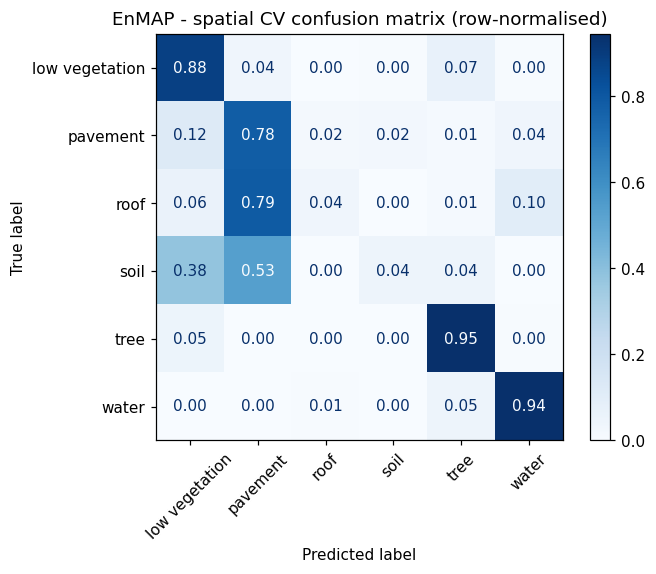

In [ ]:
blocks = (np.arange(rows)[:, None] // CFG["block_px"]) * (cols // CFG["block_px"] + 1) + \
         (np.arange(cols)[None, :] // CFG["block_px"])

def subsample(mask):
    idx = np.flatnonzero(mask)
    if len(idx) > CFG["max_samples"]:
        idx = np.sort(rng.choice(idx, CFG["max_samples"], replace=False))
    m = np.zeros(mask.size, bool); m[idx] = True
    return m.reshape(mask.shape)

def rf_classifier():
    return RandomForestClassifier(n_estimators=CFG["n_trees"], n_jobs=-1, class_weight="balanced_subsample",
                                  random_state=CFG["random_state"])

def cv_classify(features, mask, name=""):
    X, y, g = flat(features, mask), dominant[mask], blocks[mask]
    oof = np.zeros_like(y)
    cv = StratifiedGroupKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=CFG["random_state"])
    for tr, te in cv.split(X, y, g):
        oof[te] = rf_classifier().fit(X[tr], y[tr]).predict(X[te])
    res = dict(features=name, n_features=X.shape[1], OA=accuracy_score(y, oof),
               kappa=cohen_kappa_score(y, oof), macro_F1=f1_score(y, oof, average="macro"))
    return res, y, oof

samples_cls = subsample(train_cls)
F_enmap = cube_s[good]
res_e, y_true, y_oof = cv_classify(F_enmap, samples_cls, "EnMAP (all good bands)")
print({k: round(v, 3) if isinstance(v, float) else v for k, v in res_e.items()})

ConfusionMatrixDisplay.from_predictions(y_true, y_oof, display_labels=classes, normalize="true",
                                        xticks_rotation=45, values_format=".2f", cmap="Blues")
plt.title("EnMAP - spatial CV confusion matrix (row-normalised)"); plt.show()

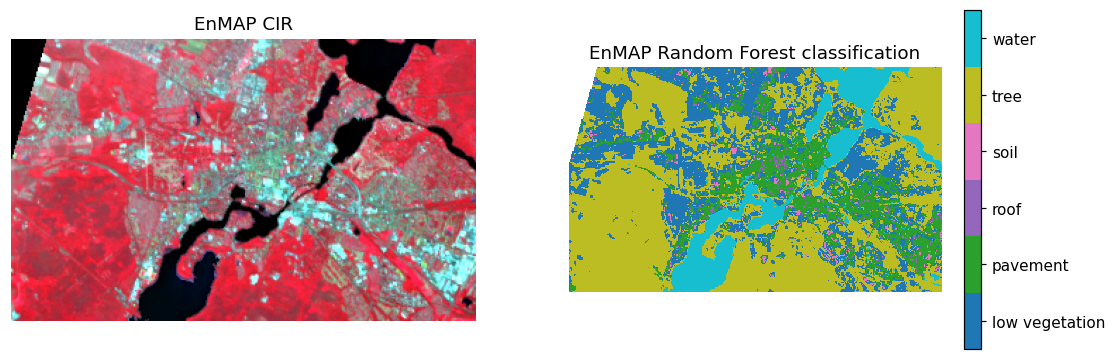

In [ ]:
def predict_map(features, train_mask, predict_mask):
    model = rf_classifier().fit(flat(features, train_mask), dominant[train_mask])
    return unflat(model.predict(flat(features, predict_mask)).astype("float32"), predict_mask), model

map_e, model_e = predict_map(F_enmap, samples_cls, valid)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(composite(cube, (860, 650, 560))); ax[0].set_title("EnMAP CIR")
im = ax[1].imshow(map_e, cmap=cmap, vmin=0.5, vmax=len(classes) + 0.5, interpolation="nearest")
cb = fig.colorbar(im, ax=ax[1], ticks=range(1, len(classes) + 1)); cb.ax.set_yticklabels(classes)
ax[1].set_title("EnMAP Random Forest classification")
for a in ax: a.axis("off")
plt.show()

## 8 · Retrieve Sentinel-2 and align it to the EnMAP grid

**Method.** Search public Sentinel-2 L2A STAC assets around the EnMAP acquisition, screen candidate scenes with the Scene Classification Layer (SCL), and resample the required bands to the **EnMAP 30 m analysis grid**. Reflectance values are obtained using asset scale/offset metadata with a fallback for the processing baseline.

**Checks before comparing sensors:**
- Verify `s2_is_real == True`. If the download fails, the fallback stack is simulated from EnMAP and **cannot demonstrate independent sensor complementarity**.
- Inspect the selected Sentinel-2 date, the actual clear fraction across the study area, and the EnMAP–Sentinel-2 date gap.
- Consider residual co-registration, atmospheric differences, mixed-pixel footprints and scene-specific spectral response.

Reprojection and resampling align grid cells, but do not establish perfect sensor co-registration.

                      id                    date     cloud  epsg  days_from_enmap  same_crs
S2A_33UUU_20220720_0_L2A 2022-07-20 10:26:21.914  1.636063 32633               -5      True
S2B_33UUU_20220804_0_L2A 2022-08-04 10:26:14.896 18.582241 32633               10      True
S2B_33UUU_20220712_0_L2A 2022-07-12 10:16:17.440  9.956232 32633              -13      True
S2A_33UUU_20220809_0_L2A 2022-08-09 10:26:22.130 24.593262 32633               15      True
S2B_33UUU_20220811_0_L2A 2022-08-11 10:16:16.554 20.319881 32633               17      True
S2A_33UUU_20220816_0_L2A 2022-08-16 10:16:25.498 17.158949 32633               22      True
S2B_33UUU_20220702_0_L2A 2022-07-02 10:16:18.147 23.845094 32633              -23      True
S2A_32UQD_20220720_0_L2A 2022-07-20 10:26:22.752  3.033998 32632               -5     False
S2A_33UUU_20220720_0_L2A: clear over AOI 100%

using S2A_33UUU_20220720_0_L2A, 5 days from EnMAP
Sentinel-2 stack (10, 200, 330), valid on EnMAP grid: 100%


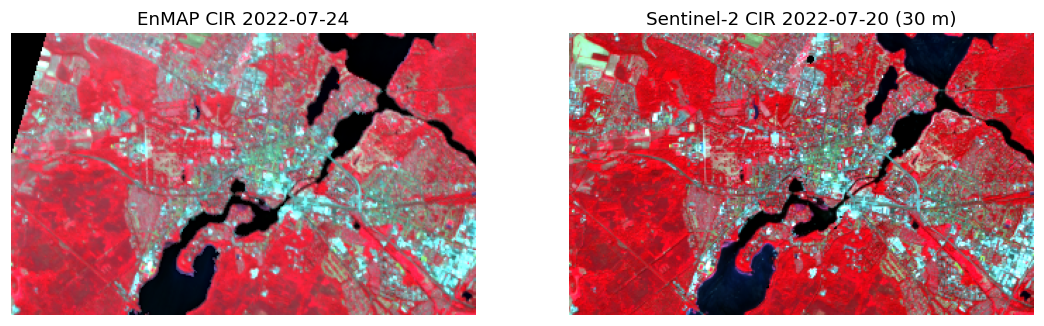

In [ ]:
# band key in Earth Search -> (S2 band, centre nm, FWHM nm)
S2_BANDS = {
    "blue": ("B02", 492, 66), "green": ("B03", 560, 36), "red": ("B04", 665, 31),
    "rededge1": ("B05", 704, 15), "rededge2": ("B06", 740, 15), "rededge3": ("B07", 783, 20),
    "nir": ("B08", 833, 106), "nir08": ("B8A", 865, 21), "swir16": ("B11", 1614, 91), "swir22": ("B12", 2202, 175),
}
s2_names = [v[0] for v in S2_BANDS.values()]

def simulate_s2(c):
    # Approximate Sentinel-2 bands from EnMAP with Gaussian spectral response functions
    out = []
    for _, (b, centre, w) in S2_BANDS.items():
        wt = np.exp(-0.5 * ((wl - centre) / (w / 2.3548)) ** 2) * good
        wt /= wt.sum()
        out.append(np.tensordot(wt[good], np.nan_to_num(c[good]), axes=1))
    out = np.stack(out).astype("float32")
    out[:, ~valid] = np.nan
    return out

def item_epsg(item):
    p = item.properties
    if "proj:epsg" in p and p["proj:epsg"]:
        return int(p["proj:epsg"])
    if "proj:code" in p and p["proj:code"]:
        return int(str(p["proj:code"]).split(":")[-1])
    return None

def asset_scale_offset(item, key):
    rb = (item.assets[key].extra_fields.get("raster:bands") or [{}])[0]
    if "scale" in rb:
        return rb["scale"], rb.get("offset", 0.0)
    pb = float(item.properties.get("s2:processing_baseline", 0) or 0)
    applied = item.properties.get("earthsearch:boa_offset_applied", False)
    return 1e-4, (-0.1 if (pb >= 4.0 and not applied) else 0.0)

def read_on_grid(href, resampling, dtype="float32"):
    env = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", AWS_NO_SIGN_REQUEST="YES",
               GDAL_HTTP_MAX_RETRY="3", GDAL_HTTP_RETRY_DELAY="2")
    with rasterio.Env(**env), rasterio.open(href) as src, \
         WarpedVRT(src, crs=meta["crs"], transform=meta["transform"], width=cols, height=rows,
                   resampling=resampling, src_nodata=0, nodata=0, dtype=dtype) as vrt:
        return vrt.read(1)

def load_s2_stac():
    from pystac_client import Client
    bbox = transform_bounds(meta["crs"], "EPSG:4326", *meta["bounds"])
    d0 = (pd.Timestamp(enmap_date) - pd.Timedelta(days=CFG["s2_window_days"])).strftime("%Y-%m-%d")
    d1 = (pd.Timestamp(enmap_date) + pd.Timedelta(days=CFG["s2_window_days"])).strftime("%Y-%m-%d")
    items = list(Client.open(CFG["stac_url"]).search(
        collections=["sentinel-2-l2a"], bbox=bbox, datetime=f"{d0}/{d1}",
        query={"eo:cloud_cover": {"lt": CFG["s2_max_cloud"]}}).items())
    if not items:
        raise RuntimeError("no Sentinel-2 scene found - widen s2_window_days or s2_max_cloud")
    epsg = meta["crs"].to_epsg()
    tab = pd.DataFrame([dict(id=i.id, date=pd.Timestamp(i.properties["datetime"]).tz_localize(None),
                             cloud=i.properties["eo:cloud_cover"], epsg=item_epsg(i)) for i in items])
    tab["days_from_enmap"] = (tab["date"] - pd.Timestamp(enmap_date)).dt.days
    tab["same_crs"] = tab["epsg"] == epsg          # prefer the tile in the EnMAP UTM zone
    tab["abs_days"] = tab["days_from_enmap"].abs()
    tab = tab.sort_values(["same_crs", "abs_days"], ascending=[False, True])
    print(tab.drop(columns="abs_days").head(8).to_string(index=False))
    # Try candidates (closest date first) until one is >= 90 % clear over the AOI; else keep the clearest
    best = None
    for _, row in tab.head(6).iterrows():
        item = next(i for i in items if i.id == row["id"])
        scl = read_on_grid(item.assets["scl"].href, Resampling.mode, "uint8")
        clear = np.isin(scl, [4, 5, 6, 7])          # vegetation, bare soil, water, unclassified
        print(f"{item.id}: clear over AOI {clear.mean():.0%}")
        if best is None or clear.mean() > best[1].mean():
            best = (item, clear)
        if clear.mean() >= 0.9:
            break
    item, clear = best
    bands = []
    for key in S2_BANDS:
        dn = read_on_grid(item.assets[key].href, Resampling.average)
        s, o = asset_scale_offset(item, key)
        b = dn * s + o
        b[dn == 0] = np.nan
        bands.append(b)
    s2 = np.stack(bands).astype("float32")
    s2[:, ~clear] = np.nan
    return s2, item.id, pd.Timestamp(item.properties["datetime"]).tz_localize(None)

s2_is_real = False
if CFG["s2_source"] == "stac":
    try:
        s2, s2_id, s2_date = load_s2_stac()
        s2_is_real = True
        print(f"\nusing {s2_id}, {abs((s2_date - pd.Timestamp(enmap_date)).days)} days from EnMAP")
    except Exception as e:
        print("!! Sentinel-2 download failed:", repr(e))
        print("!! Falling back to SIMULATED Sentinel-2 (fusion results will NOT be meaningful).")
if not s2_is_real:
    s2, s2_id, s2_date = simulate_s2(cube_s), "simulated-from-EnMAP", pd.Timestamp(enmap_date)

s2_valid = np.all(np.isfinite(s2), axis=0)
print(f"Sentinel-2 stack {s2.shape}, valid on EnMAP grid: {s2_valid.mean():.0%}")

def s2_rgb(arr, keys):
    return stretch(np.dstack([arr[s2_names.index(k)] for k in keys]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(composite(cube, (860, 650, 560))); ax[0].set_title(f"EnMAP CIR {enmap_date:%Y-%m-%d}")
ax[1].imshow(s2_rgb(s2, ("B08", "B04", "B03"))); ax[1].set_title(f"Sentinel-2 CIR {s2_date:%Y-%m-%d} (30 m)")
for a in ax: a.axis("off")
plt.show()

## 9 · Cross-sensor consistency diagnostic

**Method.** Approximate Sentinel-2 bands using Gaussian spectral-response weights applied to the EnMAP spectra; compare these synthetic bands with the retrieved Sentinel-2 observations using Pearson correlation, bias and RMSE. A phase-correlation step estimates a possible image shift.

**Interpretation.** These are **diagnostics**, not radiometric harmonisation or a validated geometric correction. The approximate response curves, differing dates and processing conventions can affect agreement. The estimated shift is not automatically applied. If Sentinel-2 is simulated because remote retrieval failed, cross-sensor agreement is circular and should not be reported as evidence of independent consistency.

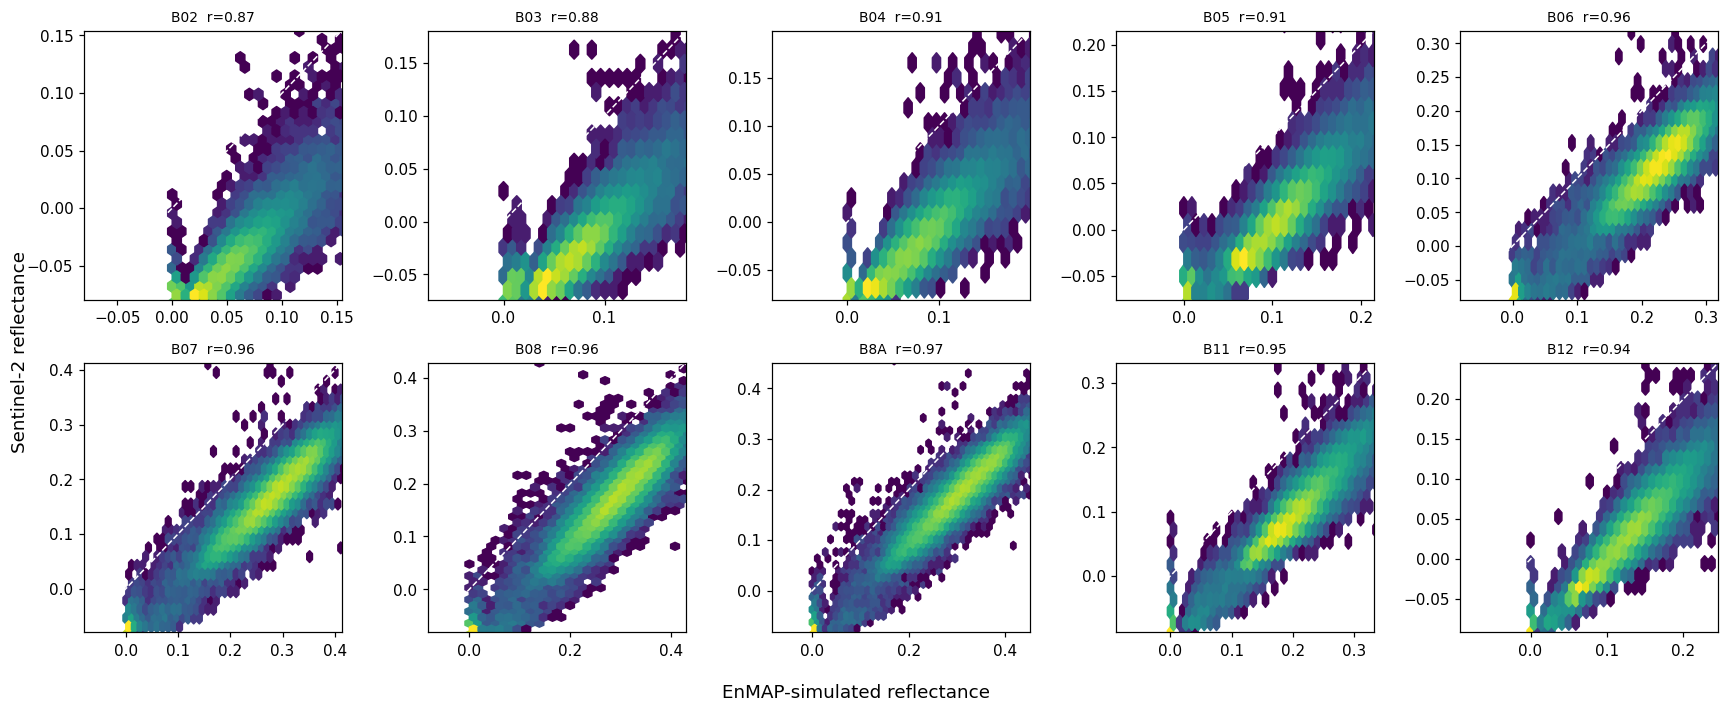

  band      r   bias   RMSE
0  B02  0.873 -0.100  0.101
1  B03  0.878 -0.099  0.101
2  B04  0.909 -0.098  0.100
3  B05  0.912 -0.097  0.098
4  B06  0.955 -0.103  0.106
5  B07  0.963 -0.109  0.112
6  B08  0.956 -0.114  0.118
7  B8A  0.968 -0.111  0.115
8  B11  0.950 -0.105  0.108
9  B12  0.941 -0.099  0.101
estimated shift S2 vs EnMAP: +0.30 rows, -0.30 cols (= +9 m, -9 m)


In [ ]:
s2_sim = simulate_s2(cube_s)
both = valid & s2_valid
rows_tab = []
fig, ax = plt.subplots(2, 5, figsize=(16, 6.5))
for i, (a, b) in enumerate(zip(ax.ravel(), s2_names)):
    x, y = s2_sim[i][both], s2[i][both]
    rows_tab.append(dict(band=b, r=np.corrcoef(x, y)[0, 1], bias=np.mean(y - x),
                         RMSE=np.sqrt(np.mean((y - x) ** 2))))
    a.hexbin(x, y, gridsize=60, bins="log", cmap="viridis", mincnt=1)
    lim = np.nanpercentile(np.r_[x, y], [0.5, 99.5]); a.plot(lim, lim, "w--", lw=1)
    a.set_xlim(lim); a.set_ylim(lim); a.set_title(f"{b}  r={rows_tab[-1]['r']:.2f}", fontsize=9)
fig.supxlabel("EnMAP-simulated reflectance"); fig.supylabel("Sentinel-2 reflectance")
plt.tight_layout(); plt.show()
consistency = pd.DataFrame(rows_tab).round(3)
display(consistency) if "display" in globals() else print(consistency)

try:
    from skimage.registration import phase_cross_correlation
    a_img = np.nan_to_num(s2_sim[s2_names.index("B8A")]); b_img = np.nan_to_num(s2[s2_names.index("B8A")])
    shift, err, _ = phase_cross_correlation(a_img, b_img, upsample_factor=10)
    print(f"estimated shift S2 vs EnMAP: {shift[0]:+.2f} rows, {shift[1]:+.2f} cols "
          f"(= {shift[0]*30:+.0f} m, {shift[1]*30:+.0f} m)")
except ImportError:
    print("install scikit-image for the co-registration check")

## 10 · Feature-level fusion for land-cover classification

**Research comparison.** Four feature representations are evaluated using the same reference samples and spatial folds:

| Feature set | Inputs |
|---|---|
| Sentinel-2 | 10 resampled bands + four indices |
| EnMAP PCA | principal components selected in section 6 |
| EnMAP full spectrum | retained hyperspectral bands |
| **Fused EnMAP + Sentinel-2** | EnMAP PCA + narrow-band indices + Sentinel-2 bands and indices |

**Fusion is early/feature-level concatenation** at a common 30 m grid; this is *not* a 10 m hyperspectral fusion product. Report overall accuracy together with **macro-F1 and per-class F1**, since rare urban classes may be poorly predicted even when overall accuracy is high.

**Caution:** the notebook fits PCA ahead of cross-validation. Fold variability, uncertainty intervals and external validation are not included. Do not claim a statistically significant fusion improvement from small aggregate metric differences.

S2 (bands+indices)     OA=0.913 kappa=0.867 macroF1=0.630
EnMAP PCA              OA=0.867 kappa=0.793 macroF1=0.570
EnMAP all bands        OA=0.876 kappa=0.809 macroF1=0.595
Fused EnMAP+S2         OA=0.916 kappa=0.871 macroF1=0.616


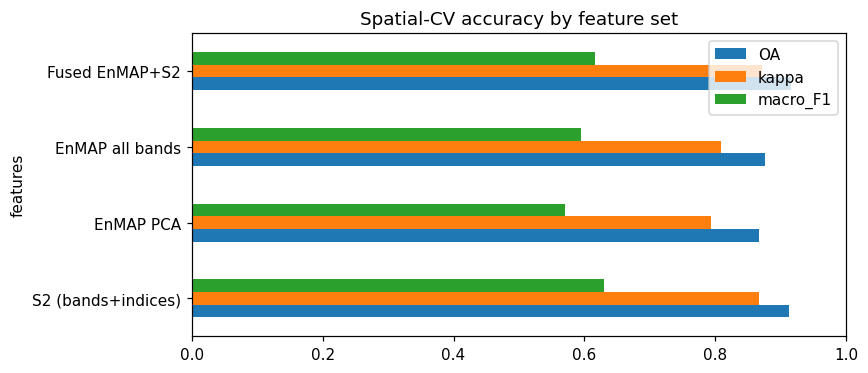

In [ ]:
def s2_indices(a):
    B = lambda k: a[s2_names.index(k)]
    return np.stack([nd(B("B08"), B("B04")), nd(B("B8A"), B("B05")),
                     nd(B("B03"), B("B08")), nd(B("B11"), B("B08"))])

feat = {
    "S2 (bands+indices)":  np.concatenate([s2, s2_indices(s2)]),
    "EnMAP PCA":           pcs[:n_pc],
    "EnMAP all bands":     F_enmap,
    "Fused EnMAP+S2":      np.concatenate([pcs[:n_pc], np.stack(list(idx_e.values())), s2, s2_indices(s2)]),
}
mask_fusion = subsample(train_cls & s2_valid)
results, oofs = [], {}
for name, f in feat.items():
    res, y_true_f, oof = cv_classify(f, mask_fusion, name)
    results.append(res); oofs[name] = oof
    print(f"{name:22s} OA={res['OA']:.3f} kappa={res['kappa']:.3f} macroF1={res['macro_F1']:.3f}")
res_cls = pd.DataFrame(results).set_index("features").round(3)

ax = res_cls[["OA", "kappa", "macro_F1"]].plot.barh(figsize=(8, 3.5))
ax.set_xlim(0, 1); ax.set_title("Spatial-CV accuracy by feature set"); plt.tight_layout(); plt.show()
if not s2_is_real:
    print("NOTE: Sentinel-2 is simulated here, so S2 and fused results are only a code test.")

                S2 (bands+indices)  EnMAP PCA  EnMAP all bands  Fused EnMAP+S2
low vegetation                0.91       0.82             0.85            0.91
pavement                      0.74       0.64             0.70            0.74
roof                          0.07       0.00             0.07            0.05
soil                          0.11       0.09             0.07            0.04
tree                          0.98       0.95             0.95            0.98
water                         0.98       0.92             0.93            0.98


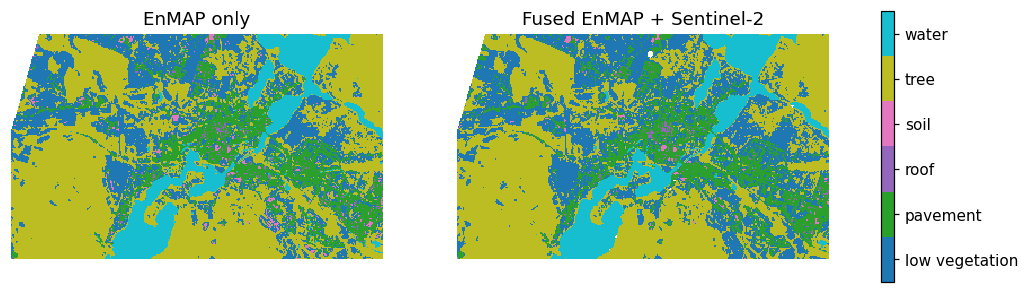

In [ ]:
# Per-class F1: where does fusion help?
per_class = pd.DataFrame({name: f1_score(y_true_f, o, average=None, labels=range(1, len(classes) + 1))
                          for name, o in oofs.items()}, index=classes).round(2)
display(per_class) if "display" in globals() else print(per_class)

fused_map, model_fused = predict_map(feat["Fused EnMAP+S2"], mask_fusion, valid & s2_valid)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (m, t) in zip(ax, [(map_e, "EnMAP only"), (fused_map, "Fused EnMAP + Sentinel-2")]):
    im = a.imshow(m, cmap=cmap, vmin=0.5, vmax=len(classes) + 0.5, interpolation="nearest")
    a.set_title(t); a.axis("off")
cb = fig.colorbar(im, ax=ax, ticks=range(1, len(classes) + 1), shrink=0.8); cb.ax.set_yticklabels(classes)
plt.show()

## 11 · Vegetation-fraction estimation

**Motivation.** Mixed 30 m urban pixels are not always well represented by a single land-cover label. This experiment instead predicts the **fraction of a pixel covered by low vegetation and trees**, as estimated from the reference polygons.

Random Forest regression is compared across the same four feature sets using grouped spatial folds. The predicted quantity is a **reference-derived fractional cover estimate**, not a physical spectral-unmixing retrieval. Temporal mismatch between imagery (2022) and labels (2019), within-pixel mixing, and model shrinkage towards the mean limit interpretation. Inspect both R² and RMSE.

                       R2   RMSE
features                        
S2 (bands+indices)  0.875  0.126
EnMAP PCA           0.786  0.165
EnMAP all bands     0.799  0.160
Fused EnMAP+S2      0.880  0.124


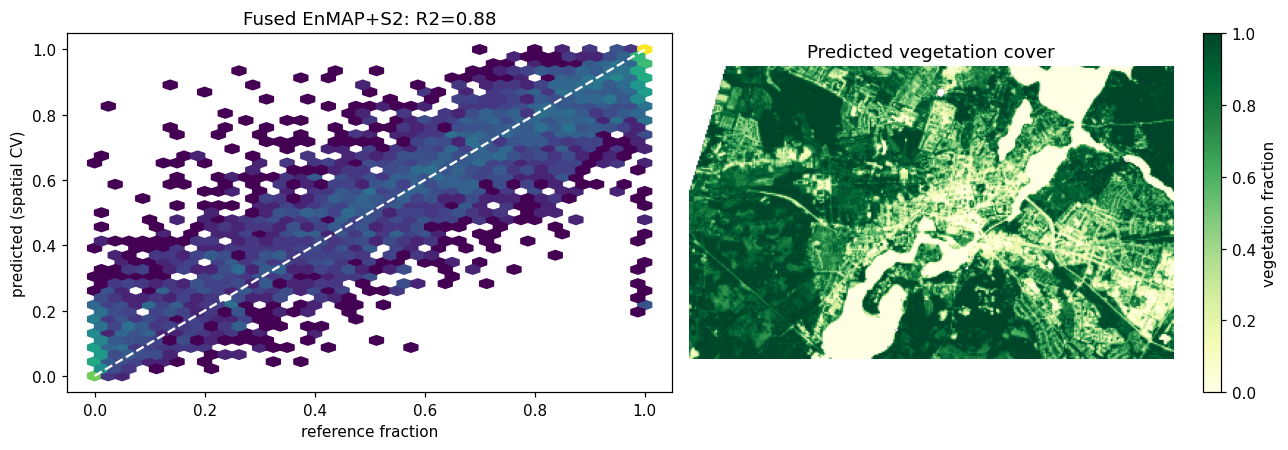

In [ ]:
def rf_regressor():
    # max_features=0.3: test 30 % of features per split (default 1.0 = all 210 bands, very slow on Colab)
    return RandomForestRegressor(n_estimators=CFG["n_trees"], n_jobs=-1, min_samples_leaf=2,
                                 max_features=0.3, random_state=CFG["random_state"])

mask_reg = subsample(covered & s2_valid)
y_reg, g_reg = veg_frac[mask_reg], blocks[mask_reg]
reg_rows, reg_oof = [], {}
for name, f in feat.items():
    X = flat(f, mask_reg)
    oof = np.zeros_like(y_reg)
    for tr, te in GroupKFold(n_splits=CFG["n_folds"]).split(X, y_reg, g_reg):
        oof[te] = rf_regressor().fit(X[tr], y_reg[tr]).predict(X[te])
    reg_oof[name] = oof
    reg_rows.append(dict(features=name, R2=r2_score(y_reg, oof), RMSE=np.sqrt(mean_squared_error(y_reg, oof))))
res_reg = pd.DataFrame(reg_rows).set_index("features").round(3)
display(res_reg) if "display" in globals() else print(res_reg)

best = res_reg["R2"].idxmax()
reg_model = rf_regressor().fit(flat(feat[best], mask_reg), y_reg)
vf_map = unflat(reg_model.predict(flat(feat[best], valid & s2_valid)).astype("float32"), valid & s2_valid)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hexbin(y_reg, reg_oof[best], gridsize=40, bins="log", cmap="viridis", mincnt=1)
ax[0].plot([0, 1], [0, 1], "w--"); ax[0].set_xlabel("reference fraction"); ax[0].set_ylabel("predicted (spatial CV)")
ax[0].set_title(f"{best}: R2={res_reg.loc[best, 'R2']:.2f}")
im = ax[1].imshow(vf_map, cmap="YlGn", vmin=0, vmax=1); ax[1].axis("off")
fig.colorbar(im, ax=ax[1], label="vegetation fraction"); ax[1].set_title("Predicted vegetation cover")
plt.tight_layout(); plt.show()

## 12 · Export products

The code writes class maps, a vegetation-fraction raster, intermediate feature rasters, CSV accuracy tables, class mappings and a fitted Random Forest classifier into `CFG['out_dir']`. Some outputs are large GeoTIFFs and need **not** be committed to GitHub. Prefer small result tables and illustrative figures in the repository; explain how the large rasters can be regenerated.

**Safety / portability:** `joblib` serialisation is Python-version and dependency sensitive, and loading an untrusted model file may execute code. Only load models you trust; where practical, reproduce training from this notebook rather than relying on the saved binary.

In [ ]:
def write_tif(arr, name, dtype="float32", nodata=np.nan, band_names=None):
    arr = np.asarray(arr)
    if arr.ndim == 2:
        arr = arr[None]
    prof = dict(driver="GTiff", width=cols, height=rows, count=arr.shape[0], dtype=dtype,
                crs=meta["crs"], transform=meta["transform"], nodata=nodata, compress="deflate")
    path = os.path.join(CFG["out_dir"], name)
    with rasterio.open(path, "w", **prof) as dst:
        dst.write(arr.astype(dtype))
        for i, bn in enumerate(band_names or [], 1):
            dst.set_band_description(i, bn)
    return path

out = [
    write_tif(np.nan_to_num(map_e, nan=0), "class_enmap.tif", "uint8", 0),
    write_tif(np.nan_to_num(fused_map, nan=0), "class_fused.tif", "uint8", 0),
    write_tif(vf_map, "vegetation_fraction.tif"),
    write_tif(s2, "s2_on_enmap_grid.tif", band_names=s2_names),
    write_tif(pcs[:n_pc], "enmap_pca.tif", band_names=[f"PC{i+1}" for i in range(n_pc)]),
    write_tif(np.stack(list(idx_e.values())), "enmap_indices.tif", band_names=list(idx_e)),
]
with open(os.path.join(CFG["out_dir"], "classes.json"), "w") as f:
    json.dump(code_of, f, indent=2)
joblib.dump(model_fused, os.path.join(CFG["out_dir"], "rf_fused_classifier.joblib"))
res_cls.to_csv(os.path.join(CFG["out_dir"], "accuracy_classification.csv"))
res_reg.to_csv(os.path.join(CFG["out_dir"], "accuracy_vegfraction.csv"))
print("\n".join(sorted(os.listdir(CFG["out_dir"]))))




accuracy_classification.csv
accuracy_vegfraction.csv
class_enmap.tif
class_fused.tif
classes.json
enmap_indices.tif
enmap_pca.tif
rf_fused_classifier.joblib
s2_on_enmap_grid.tif
vegetation_fraction.tif


In [ ]:
# Colab: download everything (shell line and Python lines must be separate):
!zip -r outputs.zip outputs
from google.colab import files
files.download('outputs.zip')


updating: outputs/ (stored 0%)
updating: outputs/enmap_indices.tif (deflated 0%)
updating: outputs/accuracy_classification.csv (deflated 24%)
updating: outputs/classes.json (deflated 21%)
updating: outputs/class_fused.tif (deflated 2%)
updating: outputs/vegetation_fraction.tif (deflated 0%)
updating: outputs/rf_fused_classifier.joblib (deflated 74%)
updating: outputs/class_enmap.tif (deflated 2%)
updating: outputs/s2_on_enmap_grid.tif (deflated 0%)
updating: outputs/enmap_pca.tif (deflated 0%)
updating: outputs/accuracy_vegfraction.csv (deflated 20%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Or copy to Google Drive:
from google.colab import drive; drive.mount('/content/drive')
!cp -r outputs "/content/drive/MyDrive/enmap_outputs"

Mounted at /content/drive


## 13 · Findings, limitations and future work

### Findings from the recorded Potsdam example run

The accompanying README records the results of a run with **real Sentinel-2** data. On that run, six-class land-cover classification achieved overall accuracy **0.913** with Sentinel-2 features versus **0.916** with stacked EnMAP + Sentinel-2 features. However, **macro-F1 decreased from 0.630 to 0.616**, and roof and soil remained poorly resolved. For vegetation-fraction regression, R² changed from **0.875** (Sentinel-2) to **0.880** (fusion), with RMSE **0.126** versus **0.124**. These small differences are **not evidence of a robust advantage for fusion**, because fold-wise variation has not been quantified.

### Interpretation

- Sentinel-2 features performed strongly on this broad-class, fine-grained urban scene even when aggregated to the EnMAP grid.
- Roof and bare-soil classes have very low F1 scores; high overall accuracy does **not** imply uniformly good land-cover mapping.
- Fractional vegetation cover is a more suitable target than a forced discrete class for many mixed pixels, but the reference fractions are imperfect labels.
- Results from a single location, image pair and historical reference dataset should be treated as a **methods demonstrator**, not a transferable operational model.

### Limitations to state in publications and applications

1. **Geographic/temporal scope:** one city and a limited set of acquisitions; aerial reference data predates the satellite images.
2. **Assessment:** spatial block CV reduces local dependence but does not substitute for independent-scene testing; fold-wise uncertainty was not reported.
3. **PCA evaluation:** PCA is fitted globally before CV rather than within each training fold; tighten the evaluation pipeline before making rigorous performance claims.
4. **Fusion scope:** only feature concatenation and Random Forest were tested, not pixel-level sharpening or physics-based unmixing.
5. **Data access:** STAC fallback simulates Sentinel-2 from EnMAP; any results from fallback runs are *code tests only*.

### Next experiments

1. Refit all learned transformations inside each CV fold and report fold-wise confidence intervals / variability.
2. Validate on a different date or geography and test sensitivity to co-registration shifts.
3. Compare spectral-sensitive targets (roof materials, vegetation traits, soil properties) with broad land-cover classes.
4. Add a Sentinel-2 time series, or evaluate explicit spatial fusion/sharpening against held-out reference data.
5. Move preprocessing and CV logic into tested Python modules for more reliable reuse.